# E-Commerce Orders 2026: Exploratory Data Analysis & Visualization
**CodeAlpha Data Analytics Internship | Task 2 (EDA) and Task 3 (Data Visualization)**

**Author:** Hafsa Hamsa  |  **Dataset:** E-commerce Orders & Transactions 2026 (Kaggle)

## Introduction
This project explores an e-commerce dataset with **200,000 orders** and **50 columns**

**Questions I want to answer:**
1. Which product categories bring the most sales and profit?
2. How do sales change month by month?
3. Do bigger discounts reduce profit?
4. How many orders are cancelled or returned?
5. Which region or category perform best?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("ecommerce_orders_transactions_2026.csv")

In [4]:
df.head()

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
0,ORD-105927,2026-02-10,11:34:55,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Neutral,False,North America,Frankfurt,Asia Consumer Goods Ltd,-51.34,-46.73,False,False,True
1,ORD-178205,2026-02-19,10:10:49,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Negative,True,North America,London,International Retail Distribution,24.30,16.34,False,False,False
2,ORD-057651,2026-07-19,11:44:02,CUST-000002,Nina Wong,23,Female,New Zealand,Oceania,Auckland,...,Neutral,False,Asia Pacific,Toronto,Premium Electronics Supply,64.77,25.86,False,False,True
3,ORD-124661,2026-08-26,18:13:21,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Positive,False,Africa,Dubai,Premium Electronics Supply,9.29,12.57,False,False,True
4,ORD-162453,2026-09-08,10:34:46,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Neutral,True,Africa,Toronto,Global Home Supplies,-15.16,-13.75,False,False,False


In [5]:
df.tail()

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
199995,ORD-122357,2026-07-05,19:25:22,CUST-074998,Liam Garcia 74997,45,Female,Portugal,Europe,Lisbon,...,Positive,False,Europe,Amsterdam,Asia Consumer Goods Ltd,146.96,39.64,False,False,True
199996,ORD-044258,2026-06-07,10:06:53,CUST-074999,Sarah Ali 74998,20,Female,Israel,Asia,Tel Aviv,...,Neutral,False,Asia Pacific,Frankfurt,Global Tech Distribution,-7.74,-4.35,False,False,True
199997,ORD-163851,2026-06-18,17:50:18,CUST-074999,Sarah Ali 74998,20,Female,Israel,Asia,Tel Aviv,...,Positive,True,Asia Pacific,Amsterdam,Quality Goods International,-7.90,-14.05,False,False,False
199998,ORD-021544,2026-10-10,15:15:26,CUST-074999,Sarah Ali 74998,20,Female,Israel,Asia,Tel Aviv,...,Positive,True,Asia Pacific,Dubai,Premium Electronics Supply,447.69,45.95,False,False,False
199999,ORD-118346,2026-11-30,14:09:16,CUST-075000,Rose Young 74999,58,Female,Sweden,Europe,Malmo,...,Neutral,False,Europe,London,Quality Goods International,-1.25,-6.54,False,True,True


In [6]:
print("Rows, Columns:", df.shape)

Rows, Columns: (200000, 50)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Order_ID                  200000 non-null  object 
 1   Order_Date                200000 non-null  object 
 2   Order_Time                200000 non-null  object 
 3   Customer_ID               200000 non-null  object 
 4   Customer_Name             200000 non-null  object 
 5   Customer_Age              200000 non-null  int64  
 6   Customer_Gender           200000 non-null  object 
 7   Customer_Country          200000 non-null  object 
 8   Customer_Continent        200000 non-null  object 
 9   Customer_City             200000 non-null  object 
 10  Customer_Region           200000 non-null  object 
 11  Customer_Segment          200000 non-null  object 
 12  Product_ID                200000 non-null  object 
 13  SKU                       200000 non-null  o

In [8]:
df.describe()

,Customer_Age,Quantity,Unit_Price_USD,Gross_Sales_USD,Discount_Percentage,Discount_Amount_USD,Net_Sales_USD,Tax_Rate_Percentage,Tax_USD,Shipping_Cost_USD,Total_Order_Value_USD,Delivery_Days,Customer_Rating,Order_Profit_USD,Profit_Margin_Percentage
count,200000.000000,200000.000000,200000.0000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,46.468095,2.099710,285.8525,600.886376,12.031875,72.190930,528.695447,15.688187,82.907388,15.789273,627.392108,5.276760,3.875603,152.470468,10.045555
std,16.744957,1.179125,376.9972,970.303038,10.335958,164.842379,861.969610,6.743041,151.308301,10.549840,999.635282,4.425006,0.822704,328.661830,47.494389
min,18.000000,1.000000,5.0000,5.000000,0.000000,0.000000,3.300000,0.000000,0.000000,3.000000,8.820000,0.000000,1.000000,-1325.470000,-1445.040000
25%,32.000000,1.000000,50.0200,79.250000,5.000000,2.670000,68.667500,10.000000,8.730000,8.680000,95.190000,3.000000,3.600000,1.270000,1.620000
50%,46.000000,2.000000,93.7600,199.380000,10.000000,15.460000,177.400000,17.000000,25.130000,13.340000,221.360000,4.000000,4.000000,33.350000,19.530000
75%,61.000000,3.000000,348.4200,672.310000,20.000000,61.290000,584.842500,21.000000,83.112500,18.840000,691.627500,6.000000,4.500000,147.362500,33.710000
max,75.000000,5.000000,1499.2800,7494.350000,40.000000,2988.220000,7494.350000,27.000000,1875.920000,60.000000,9285.860000,25.000000,5.000000,4280.540000,59.850000


In [9]:
df.describe(include="object")

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,Customer_Region,...,Shipping_Method,Return_Status,Return_Reason,Marketing_Channel,Device_Type,Coupon_Code,Review_Sentiment,Sales_Region,Warehouse,Supplier
count,200000,200000,200000,200000,200000,200000,200000,200000,200000,200000,...,200000,200000,8330,200000,200000,29835,200000,200000,200000,200000
unique,200000,352,67367,69728,69728,4,51,6,208,187,...,5,2,8,10,3,12,3,5,12,9
top,ORD-052120,2026-11-06,09:55:36,CUST-017913,Carlos Robinson 17912,Male,Czech Republic,Europe,Doha,Doha,...,Standard,No Return,Changed Mind,Display Advertising,Mobile,FLASH20,Positive,Asia Pacific,London,Urban Fashion Wholesale
freq,1,822,17,12,12,95955,4203,74381,3914,3914,...,100015,191670,1088,20149,109851,2554,108448,77895,16883,22488


**What I notice:**
- 200,000 orders and 50 columns.
- `Order_Profit_USD` has negative values, so some orders lose money.
- `Return_Reason` and `Coupon_Code` show missing values(N/A).

## Data Cleaning

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

Order_ID                         0
Order_Date                       0
Order_Time                       0
Customer_ID                      0
Customer_Name                    0
Customer_Age                     0
Customer_Gender                  0
Customer_Country                 0
Customer_Continent               0
Customer_City                    0
Customer_Region                  0
Customer_Segment                 0
Product_ID                       0
SKU                              0
Product_Name                     0
Product_Category                 0
Product_Subcategory              0
Brand                            0
Quantity                         0
Unit_Price_USD                   0
Gross_Sales_USD                  0
Discount_Percentage              0
Discount_Amount_USD              0
Net_Sales_USD                    0
Tax_Rate_Percentage              0
Tax_USD                          0
Shipping_Cost_USD                0
Total_Order_Value_USD            0
Payment_Method      

In [12]:
missing = df.isnull().sum()
missing[missing > 0]

Return_Reason    191670
Coupon_Code      170165
dtype: int64

These "missing" values are not errors. In the raw file they are written as `N/A`, which pandas reads as empty.
- `Return_Reason` is empty when there was **no return**.
- `Coupon_Code` is empty when **no coupon was used**.

So I fill them with clear labels instead of deleting any rows.

In [13]:
df["Return_Reason"] = df["Return_Reason"].fillna("No Return")
df["Coupon_Code"] = df["Coupon_Code"].fillna("No Coupon")

In [14]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

In [15]:
df["Month"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%b")

In [16]:
df["Order_Date"].dtype

dtype('<M8[ns]')

To examine things related to date, it is better to be arranged in an order.

In [17]:
df = df.sort_values(by="Order_Date", ascending=True)

In [18]:
df.head()

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order,Month,Month_Name
153031,ORD-186326,2026-01-01,17:33:16,CUST-057334,Ethan Mendoza 57333,23,Female,Egypt,Africa,Giza,...,Africa,Karachi,Global Tech Distribution,295.00,45.72,False,False,True,1,Jan
184168,ORD-160407,2026-01-01,18:25:39,CUST-069125,Charlotte Jones 69124,29,Male,Ireland,Europe,Cork,...,Europe,Singapore,Global Tech Distribution,24.87,33.56,False,False,True,1,Jan
28718,ORD-179034,2026-01-01,11:04:32,CUST-010773,Kenji Fernandez 10772,64,Female,Austria,Europe,Graz,...,Europe,Dubai,Urban Fashion Wholesale,17.14,16.06,False,False,True,1,Jan
149251,ORD-014849,2026-01-01,15:57:02,CUST-055877,Rose Singh 55876,74,Male,Denmark,Europe,Copenhagen,...,Europe,Karachi,Urban Fashion Wholesale,25.07,21.33,False,False,True,1,Jan
66887,ORD-057366,2026-01-01,10:36:36,CUST-025055,Mohammed Allen 25054,35,Male,Belgium,Europe,Brussels,...,Europe,Frankfurt,Global Tech Distribution,12.55,20.45,False,False,True,1,Jan


In [19]:
print("Negative profit orders:", (df["Order_Profit_USD"] < 0).sum(),
      f"({(df['Order_Profit_USD'] < 0).mean():.1%})")
print("Date range:", df["Order_Date"].min().date(), "to", df["Order_Date"].max().date())

Negative profit orders: 46971 (23.5%)
Date range: 2026-01-01 to 2026-12-31


**Cleaning summary:** No duplicates, no real missing values, date column converted, month columns added. The dataset was already quite clean, so no rows were removed.

## Exploratory Data Analysis

### Key business numbers

In [20]:
print(f"Total Orders       : {len(df):,}")
print(f"Total Net Sales    : ${df['Net_Sales_USD'].sum():,.0f}")
print(f"Total Profit       : ${df['Order_Profit_USD'].sum():,.0f}")

Total Orders       : 200,000
Total Net Sales    : $105,739,089
Total Profit       : $30,494,094


### Which categories bring the most sales and profit?

In [21]:
category = df.groupby("Product_Category")[["Net_Sales_USD", "Order_Profit_USD"]].sum()
category = category.sort_values("Net_Sales_USD", ascending=False)
category.head(10).round(0)

,Net_Sales_USD,Order_Profit_USD
Product_Category,,
Electronics,28535620.0,8749423.0
Mobile Phones,24628034.0,7843767.0
Computers & Accessories,23146477.0,6970269.0
Home & Kitchen,7902875.0,2243802.0
Fashion,5747822.0,1483977.0
Furniture,4823934.0,1313614.0
Jewelry & Accessories,1922297.0,493847.0
Beauty & Personal Care,1355818.0,190791.0
Sports & Fitness,1049707.0,159303.0


In [22]:
print(df["Order_Status"].value_counts())
print()
print(df["Order_Status"].value_counts(normalize=True).mul(100).round(1))

Order_Status
Delivered     140112
Processing     19887
Shipped        15987
Cancelled      12019
Returned       11995
Name: count, dtype: int64

Order_Status
Delivered     70.1
Processing     9.9
Shipped        8.0
Cancelled      6.0
Returned       6.0
Name: proportion, dtype: float64


### Outliers in profit

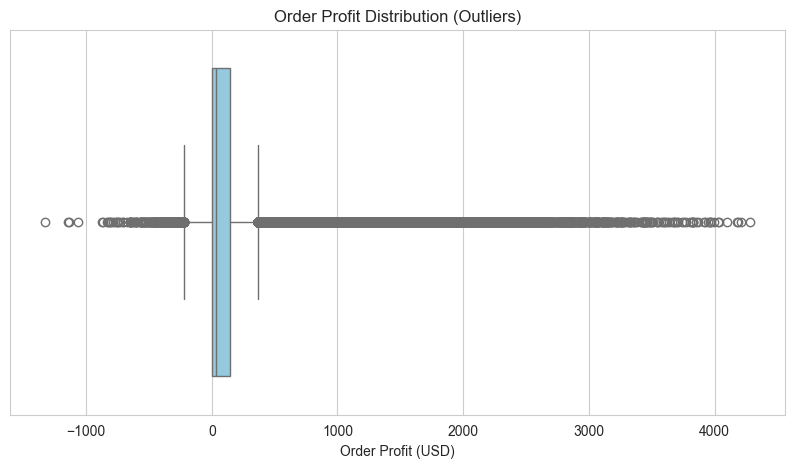

In [23]:
sns.boxplot(x=df["Order_Profit_USD"], color="skyblue")
plt.title("Order Profit Distribution (Outliers)")
plt.xlabel("Order Profit (USD)")
plt.show()

The box plot shows many extreme values on both sides. Some orders make a very high profit and some lose a lot of money.

### Correlation between numeric columns

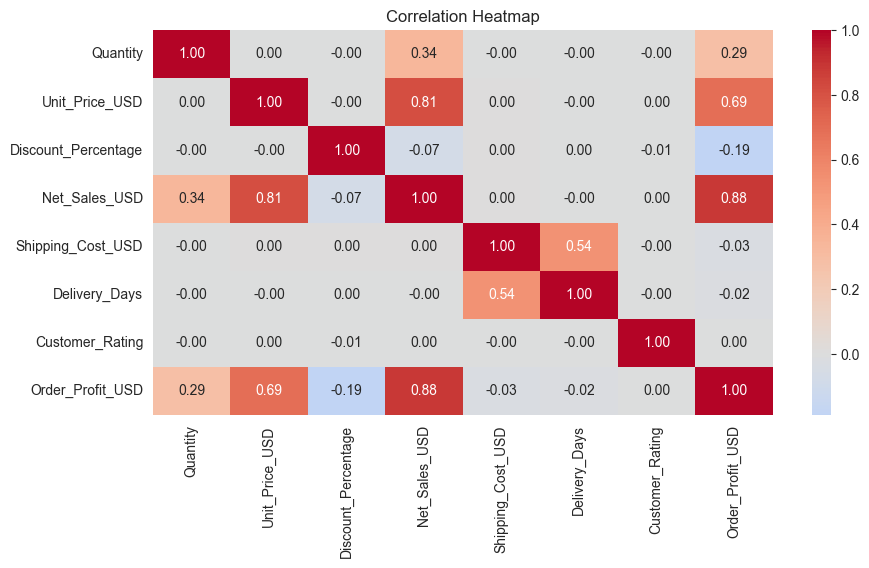

In [24]:
cols = ["Quantity", "Unit_Price_USD", "Discount_Percentage", "Net_Sales_USD",
        "Shipping_Cost_USD", "Delivery_Days", "Customer_Rating", "Order_Profit_USD"]
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

Values close to +1 or -1 mean a strong relationship, and values close to 0 mean almost none.
Look at the `Order_Profit_USD` row to see what moves with profit, and notice that `Delivery_Days` and `Customer_Rating` show almost no relationship.

## Hypothesis Testing

H0 : Higher discount reduce profit

H1 : Higher discount do not reduce profit

In [25]:
discount_profit = df.groupby("Discount_Percentage")["Order_Profit_USD"].mean().round(2)
discount_profit

Discount_Percentage
0.0     225.65
5.0     191.78
7.5     180.72
10.0    165.05
12.5    147.93
15.0    137.75
20.0    106.07
25.0     73.23
30.0     44.32
35.0     14.74
40.0    -16.35
Name: Order_Profit_USD, dtype: float64

In [26]:
corr = df["Discount_Percentage"].corr(df["Order_Profit_USD"])
print("Correlation between Discount and Profit:", round(corr, 3))

Correlation between Discount and Profit: -0.189


**Result: Do not reject H0.** Average profit falls steadily as the discount grows, and at 40% the average order loses money.

## Data Visualization

### Chart 1: Top 10 categories by net sales

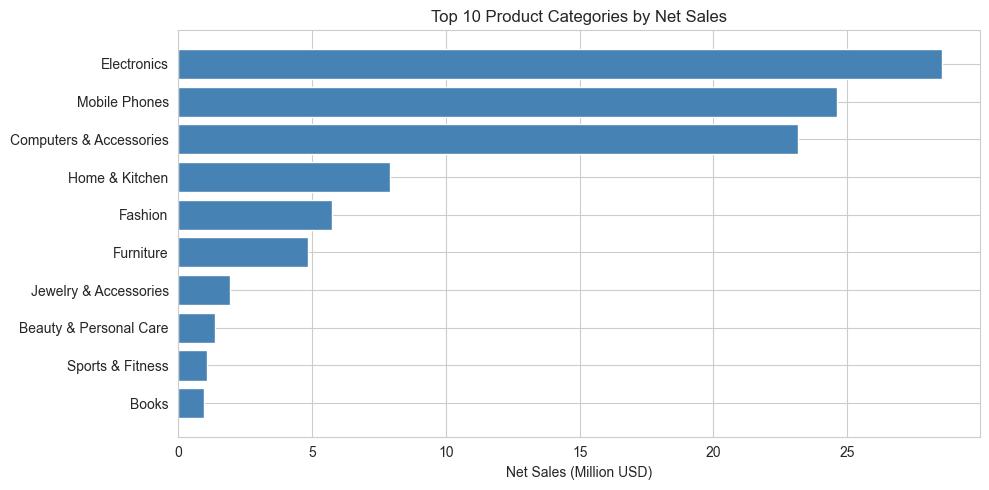

In [27]:
top10 = category.head(10).sort_values("Net_Sales_USD")
plt.barh(top10.index, top10["Net_Sales_USD"] / 1e6, color="steelblue")
plt.title("Top 10 Product Categories by Net Sales")
plt.xlabel("Net Sales (Million USD)")
plt.tight_layout()
plt.show()

### Chart 2: Monthly sales trend

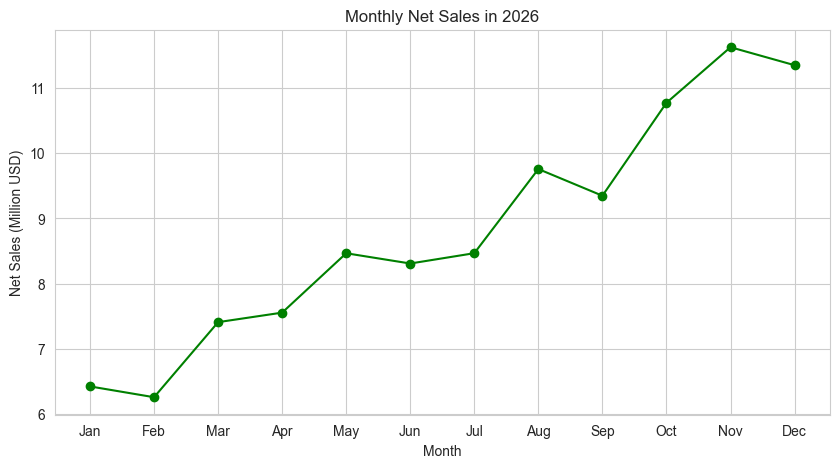

In [28]:
monthly_sales = df.groupby("Month")["Net_Sales_USD"].sum() / 1e6
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="green")
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.title("Monthly Net Sales in 2026")
plt.xlabel("Month")
plt.ylabel("Net Sales (Million USD)")
plt.show()

### Chart 3: Discount vs average profit

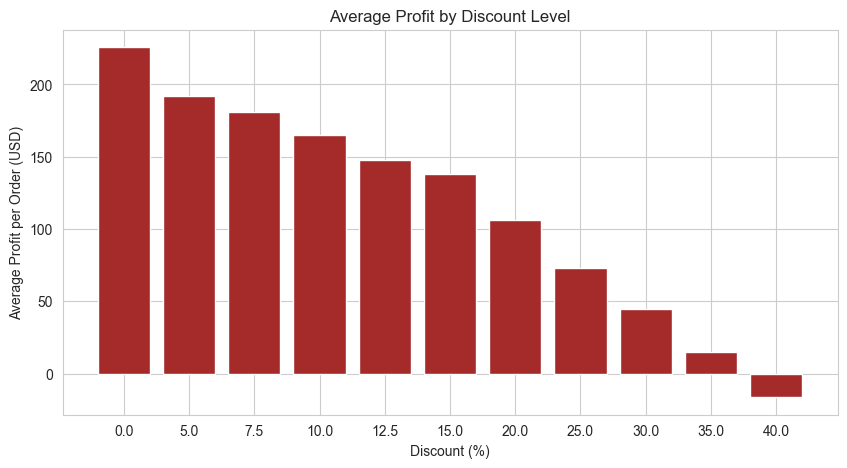

In [32]:
plt.bar(discount_profit.index.astype(str), discount_profit.values, color="brown")
plt.title("Average Profit by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit per Order (USD)")
plt.show()

Here we can see that average profit is clearly decreasing over discount

### Chart 4: Product category with quantity and profit

In [34]:
Category_count = df.groupby("Product_Category")["Quantity"].sum().reset_index()

In [35]:
Category_profit = df.groupby("Product_Category")["Order_Profit_USD"].sum().reset_index()

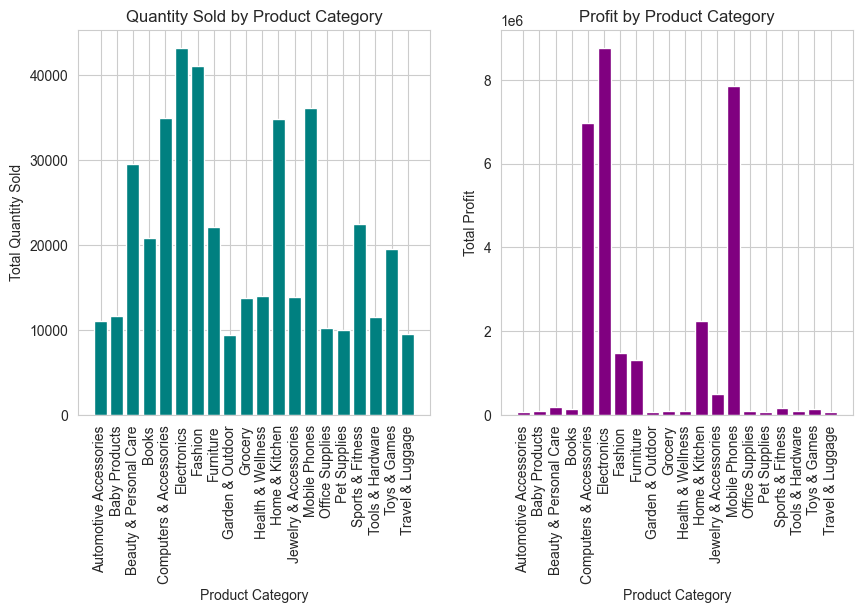

In [36]:
plt.subplot(1,2,1)

plt.bar(Category_count['Product_Category'], Category_count['Quantity'], color='teal')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.title('Quantity Sold by Product Category')
plt.xticks(rotation=90)

plt.subplot(1,2,2)

plt.bar(Category_profit['Product_Category'], Category_profit['Order_Profit_USD'], color='purple')
plt.xlabel('Product Category')
plt.ylabel('Total Profit')
plt.title('Profit by Product Category')
plt.xticks(rotation=90)

plt.show()

We can find out that not all the high-selling categories earn higher profits. But few high-selling categories earn large profits. **Electronics, Computers & Accessories and Mobile Phones** are sold more. At the same time those categories earn **large profits**.

It is noticeable that **Fashion and Home & Kitchen** categories are also sold large amount but those categories earn **less profits**.

### Chart 5: Order status

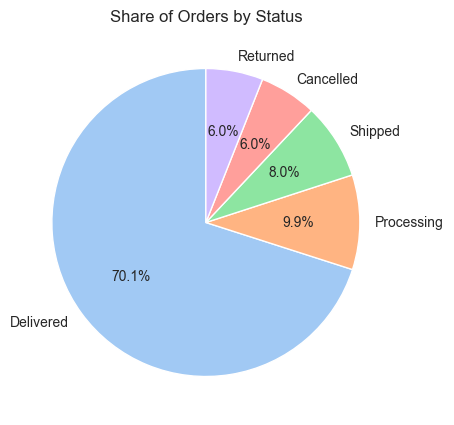

In [37]:
status = df["Order_Status"].value_counts()
plt.pie(status.values, labels=status.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("pastel"))
plt.title("Share of Orders by Status")
plt.show()

### Chart 6: Sales by region

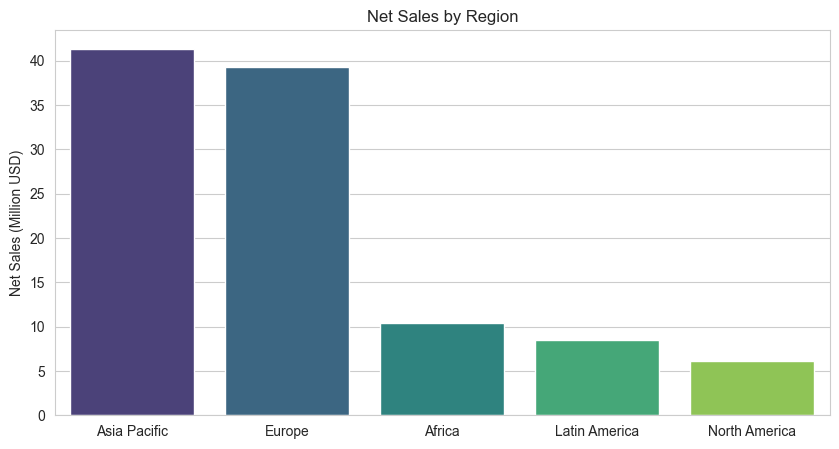

In [38]:
region = df.groupby("Sales_Region")["Net_Sales_USD"].sum().sort_values(ascending=False) / 1e6
sns.barplot(x=region.index, y=region.values, hue=region.index, palette="viridis", legend=False)
plt.title("Net Sales by Region")
plt.xlabel("")
plt.ylabel("Net Sales (Million USD)")
plt.show()

### Chart 7: Customer rating distribution

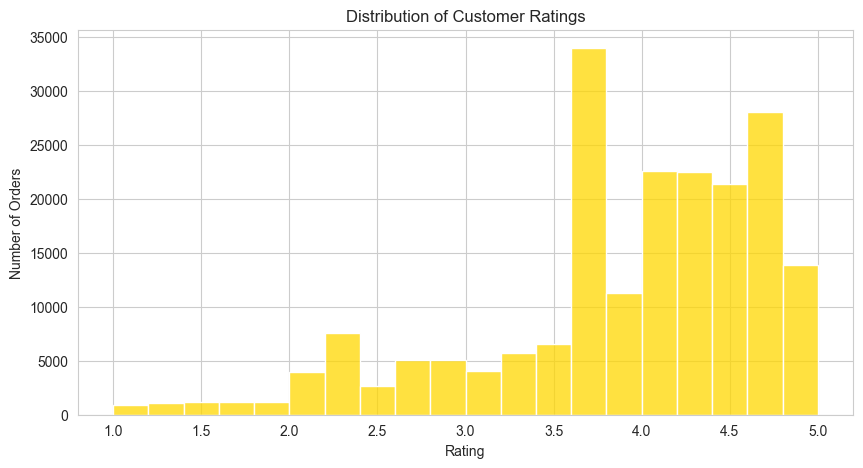

In [39]:
sns.histplot(df["Customer_Rating"], bins=20, color="gold")
plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Orders")
plt.show()

## Key Insights and Conclusion

In [40]:
df.groupby(df["Product_Category"])["Net_Sales_USD"].sum().sort_values(ascending=False)

Product_Category
Electronics                28535620.09
Mobile Phones              24628033.91
Computers & Accessories    23146477.00
Home & Kitchen              7902874.57
Fashion                     5747821.80
Furniture                   4823933.61
Jewelry & Accessories       1922297.37
Beauty & Personal Care      1355817.51
Sports & Fitness            1049706.72
Books                        943343.40
Toys & Games                 911822.71
Health & Wellness            657708.33
Grocery                      647173.95
Tools & Hardware             554827.92
Baby Products                536395.02
Automotive Accessories       528377.32
Office Supplies              499198.60
Pet Supplies                 459925.84
Garden & Outdoor             445189.57
Travel & Luggage             442544.10
Name: Net_Sales_USD, dtype: float64

Net sales are heavily concentrated in consumer technology. Electronics, Mobile Phones, and Computers & Accessories together generate roughly **$76.3M**, or **72%** of the **$105.7M** total. Home & Kitchen, Fashion, and Furniture form a second tier **($4.8M–$7.9M each)**, while the remaining 14 categories each contribute less than **2%** of revenue.

### Main findings
1. **Sales are concentrated:** Electronics, Mobile Phones and Computers & Accessories bring in about 72% of all net sales.
2. **Discounts reduce profit:** average profit drops as discounts increase, and 40% discounts lose money on average.
3. **About 12% of orders are lost:** cancelled (6%) and returned (6%) orders together are roughly 1 in 8 orders.
4. **Many orders lose money:** around 23% of orders have negative profit.

### Recommendations
- Focus marketing and stock on the top categories.
- Limit discounts above 30% unless the product has a high margin.
- Look into the reasons for returns and cancellations to reduce lost orders.

### Limitations
The dataset appears to be generated, so some patterns may be more uniform than real-world data.